# 01 - Exploratory Data Analysis

Goal: understand the structure, quality and predictive signals of the data **before** feature engineering.

Guiding questions:
1. What does a record look like? Are there missing values, anomalies, incomplete battles?
2. Is the target balanced?
3. How much do **P1's team** (stats, types, items) and **P2's lead** matter?
4. What does the **timeline of the first 30 turns** tell us (HP, KOs, status, switches, boosts)?
5. Which signals "at turn 30" separate wins from losses?

> Rule: the test set is used here **only** for descriptive checks (species coverage, format). No feature or model choice is based on the test set.

## 0. Setup

In [1]:
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RNG = 42

# Works both on Kaggle and locally (repo root or notebooks/)
CANDIDATES = [
    Path("/kaggle/input/competitions/fds-pokemon-battles-prediction-2026"),
    Path("../data/raw"),
    Path("data/raw"),
]
DATA_DIR = next(p for p in CANDIDATES if (p / "train.jsonl").exists())
print("Data dir:", DATA_DIR.resolve())

Data dir: D:\FDS Challenge\PokePredict\data\raw


In [2]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]

train = load_jsonl(DATA_DIR / "train.jsonl")
test = load_jsonl(DATA_DIR / "test.jsonl")
type_chart = pd.read_csv(DATA_DIR / "type_chart_gen2.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print(f"train: {len(train):,} battles | test: {len(test):,} battles")
print("train keys:", list(train[0].keys()))
print("test keys: ", list(test[0].keys()))

train: 10,000 battles | test: 5,000 battles
train keys: ['battle_id', 'p1_team_details', 'p2_lead_details', 'battle_timeline', 'player_won']
test keys:  ['battle_id', 'p1_team_details', 'p2_lead_details', 'battle_timeline']


## 1. Structure of a record

In [3]:
b = train[0]
print("battle_id:", b["battle_id"], "| player_won:", b["player_won"])
display(pd.DataFrame(b["p1_team_details"]))
print("P2 lead:"); display(pd.Series(b["p2_lead_details"]))
print("Turn 1:"); print(json.dumps(b["battle_timeline"][0], indent=2))

battle_id: 0 | player_won: 0


,name,level,types,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,item
0,tyranitar,100,"[dark, rock]",100,134,110,95,100,61,leftovers
1,typhlosion,100,"[fire, notype]",78,84,78,109,85,100,mintberry
2,golem,100,"[ground, rock]",80,110,130,55,65,45,berserkgene
3,umbreon,100,"[dark, notype]",95,65,110,60,130,65,leftovers
4,alakazam,100,"[notype, psychic]",55,50,45,135,85,120,leftovers
5,raikou,100,"[electric, notype]",90,85,75,115,100,115,leftovers


P2 lead:


name          forretress
level                100
types       [bug, steel]
base_hp               75
base_atk              90
base_def             140
base_spa              60
base_spd              60
base_spe              40
dtype: object

Turn 1:
{
  "turn": 1,
  "p1_pokemon_state": {
    "name": "tyranitar",
    "hp_pct": 1.0,
    "status": "nostatus",
    "effects": [
      "noeffect"
    ],
    "boosts": {
      "atk": 0,
      "def": 0,
      "spa": 0,
      "spd": 0,
      "spe": 0
    }
  },
  "p1_move_details": {
    "name": "earthquake",
    "type": "ground",
    "category": "physical",
    "base_power": 100,
    "accuracy": 1.0,
    "priority": 0
  },
  "p2_pokemon_state": {
    "name": "forretress",
    "hp_pct": 0.86,
    "status": "nostatus",
    "effects": [
      "noeffect"
    ],
    "boosts": {
      "atk": 0,
      "def": 0,
      "spa": 0,
      "spd": 0,
      "spe": 0
    }
  },
  "p2_move_details": {
    "name": "toxic",
    "type": "poison",
    "category": "status",
    "base_power": 0,
    "accuracy": 0.85,
    "priority": 0
  }
}


### 1.1 Quality checks

In [4]:
def quality_report(data, name):
    ids = [x["battle_id"] for x in data]
    rep = {
        "n_battles": len(data),
        "unique battle_id": len(set(ids)) == len(ids),
        "P1 team != 6": sum(len(x["p1_team_details"]) != 6 for x in data),
        "timeline != 30 turns": sum(len(x["battle_timeline"]) != 30 for x in data),
        "level != 100": sum(p["level"] != 100 for x in data for p in x["p1_team_details"]),
        "missing item (P1)": sum(p.get("item") in (None, "") for x in data for p in x["p1_team_details"]),
    }
    return pd.Series(rep, name=name)

display(pd.concat([quality_report(train, "train"), quality_report(test, "test")], axis=1))
print("sample_submission:", sample_sub.shape, list(sample_sub.columns))

,train,test
n_battles,10000,5000
unique battle_id,True,True
P1 team != 6,0,0
timeline != 30 turns,0,0
level != 100,360,204
missing item (P1),0,0


sample_submission: (5000, 2) ['battle_id', 'player_won']


## 2. Target

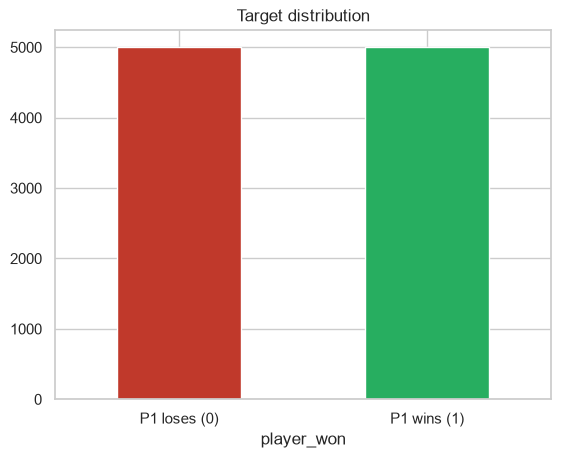

player_won
0    0.5
1    0.5
Name: proportion, dtype: float64


In [5]:
y = pd.Series([x["player_won"] for x in train], name="player_won").astype(int)
ax = y.value_counts().sort_index().plot.bar(color=["#c0392b", "#27ae60"])
ax.set_xticklabels(["P1 loses (0)", "P1 wins (1)"], rotation=0)
ax.set_title("Target distribution"); plt.show()
print(y.value_counts(normalize=True).round(4))

Balanced classes → accuracy is a sensible metric and the 'majority class' baseline is ~50%.

## 3. Player 1's team

We build a *long* table (one row per P1 Pokémon) and an aggregated table per battle.

In [6]:
STATS = ["base_hp", "base_atk", "base_def", "base_spa", "base_spd", "base_spe"]

rows = []
for x in train:
    for slot, p in enumerate(x["p1_team_details"]):
        rows.append({"battle_id": x["battle_id"], "slot": slot, "name": p["name"],
                     "type1": p["types"][0], "type2": p["types"][1], "item": p.get("item"),
                     **{s: p[s] for s in STATS}, "player_won": x["player_won"]})
p1_long = pd.DataFrame(rows)
p1_long["bst"] = p1_long[STATS].sum(axis=1)
print("Distinct species in P1 (train):", p1_long["name"].nunique())
p1_long.head()

Distinct species in P1 (train): 237


,battle_id,slot,name,type1,type2,item,base_hp,base_atk,base_def,base_spa,base_spd,base_spe,player_won,bst
0,0,0,tyranitar,dark,rock,leftovers,100,134,110,95,100,61,0,600
1,0,1,typhlosion,fire,notype,mintberry,78,84,78,109,85,100,0,534
2,0,2,golem,ground,rock,berserkgene,80,110,130,55,65,45,0,485
3,0,3,umbreon,dark,notype,leftovers,95,65,110,60,130,65,0,525
4,0,4,alakazam,notype,psychic,leftovers,55,50,45,135,85,120,0,490


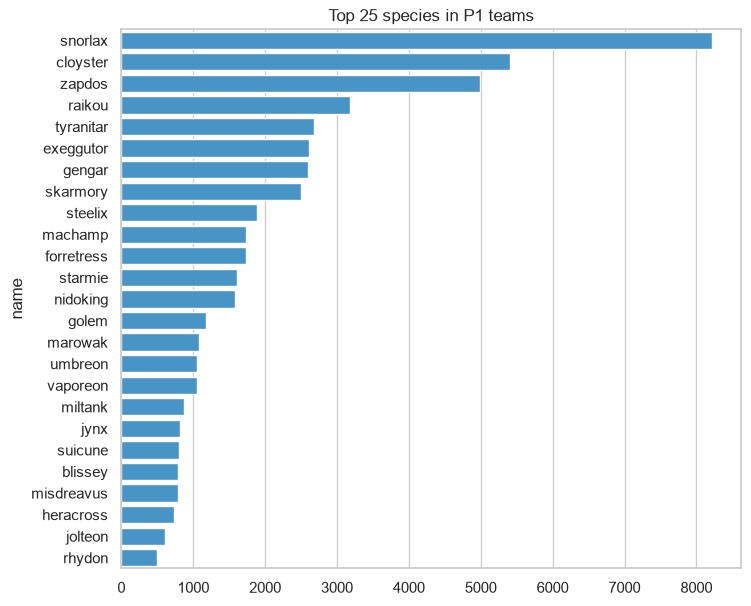

In [7]:
top = p1_long["name"].value_counts().head(25)
plt.figure(figsize=(8, 7)); sns.barplot(x=top.values, y=top.index, color="#3498db")
plt.title("Top 25 species in P1 teams"); plt.show()

### 3.1 Do team stats predict the outcome?

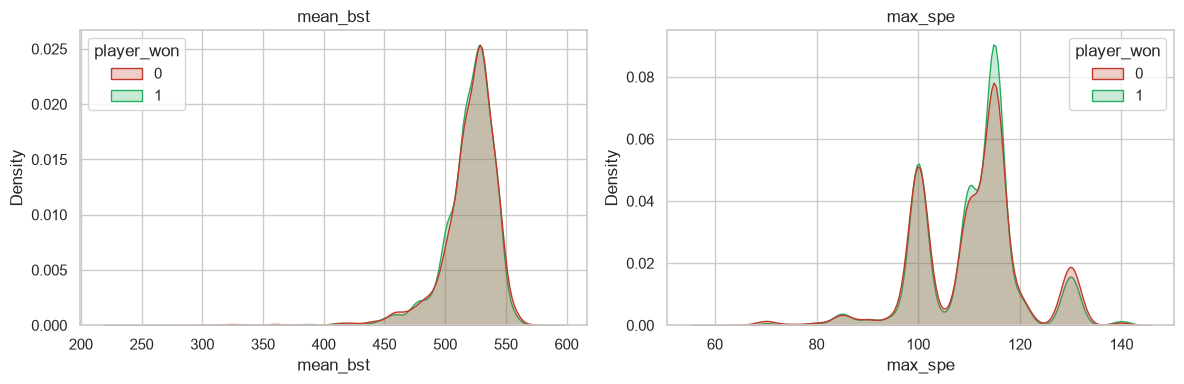

Pearson correlation with player_won:
mean_base_hp    -0.024
mean_base_spd   -0.014
mean_base_atk   -0.009
mean_bst         0.000
mean_base_spe    0.003
mean_base_spa    0.006
max_spe          0.006
mean_base_def    0.029
Name: player_won, dtype: float64


In [8]:
team = p1_long.groupby("battle_id").agg(
    **{f"mean_{s}": (s, "mean") for s in STATS + ["bst"]},
    max_spe=("base_spe", "max"),
    player_won=("player_won", "first"),
)
# Two representative distributions; the correlation table below covers all of them
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["mean_bst", "max_spe"]):
    sns.kdeplot(data=team, x=col, hue="player_won", common_norm=False, fill=True, ax=ax, palette=["#c0392b", "#27ae60"])
    ax.set_title(col)
plt.tight_layout(); plt.show()

corr = team.corr(numeric_only=True)["player_won"].drop("player_won").sort_values()
print("Pearson correlation with player_won:"); print(corr.round(3))

### 3.2 Win rate by species and by item (train only)

P1's win rate when a species (or item) is in the team. Only categories with enough appearances are shown,
with a 95% confidence interval (normal approximation) so as not to over-interpret noise.

> Note: if we later use this as a feature (target encoding), it **must be computed inside the CV folds**.

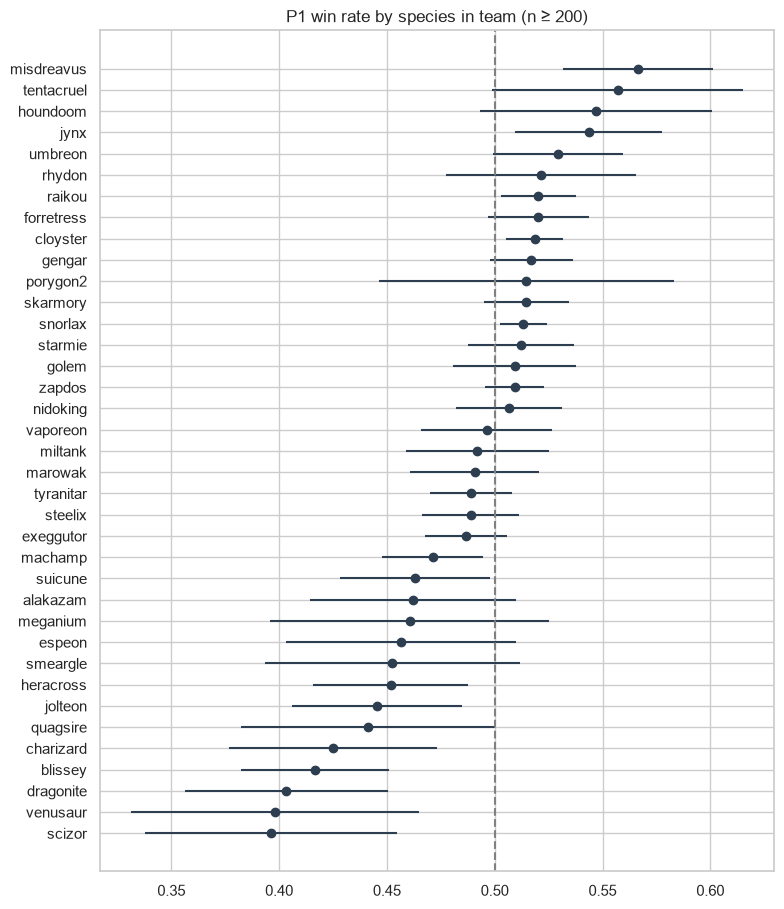

,n,win_rate,ci95
name,,,
gengar,2602,0.516910,0.019201
cloyster,5411,0.518573,0.013313
forretress,1734,0.520185,0.023515
raikou,3179,0.520289,0.017367
rhydon,491,0.521385,0.044186
umbreon,1058,0.529301,0.030077
jynx,815,0.543558,0.034197
houndoom,329,0.547112,0.053789
tentacruel,280,0.557143,0.058182


In [9]:
def winrate_table(df, key, min_n=200):
    g = df.groupby(key)["player_won"].agg(n="size", win_rate="mean")
    g = g[g["n"] >= min_n].copy()
    g["ci95"] = 1.96 * np.sqrt(g["win_rate"] * (1 - g["win_rate"]) / g["n"])
    return g.sort_values("win_rate")

wr = winrate_table(p1_long, "name")
plt.figure(figsize=(8, max(4, 0.25 * len(wr))))
plt.errorbar(wr["win_rate"], wr.index, xerr=wr["ci95"], fmt="o", color="#2c3e50")
plt.axvline(y.mean(), ls="--", c="grey"); plt.title("P1 win rate by species in team (n ≥ 200)")
plt.tight_layout(); plt.show()
wr.tail(10)

In [10]:
wr_item = winrate_table(p1_long, "item", min_n=100)
display(wr_item)

,n,win_rate,ci95
item,,,
goldberry,102,0.401961,0.095151
thickclub,1057,0.492904,0.030140
miracleberry,750,0.493333,0.035781
charcoal,104,0.500000,0.096097
leftovers,57329,0.501160,0.004093
mintberry,210,0.519048,0.067577


## 4. Player 2's lead and initial matchup

In [11]:
lead = pd.DataFrame([{**{k: v for k, v in x["p2_lead_details"].items() if k != "types"},
                      "p2_type1": x["p2_lead_details"]["types"][0], "p2_type2": x["p2_lead_details"]["types"][1],
                      "p1_lead": x["p1_team_details"][0]["name"],
                      "p1_first_active": x["battle_timeline"][0]["p1_pokemon_state"]["name"],
                      "player_won": x["player_won"]} for x in train])
print("Distinct species as P2 lead:", lead["name"].nunique())
print("Is P1's first active Pokémon team slot 0?", (lead["p1_lead"] == lead["p1_first_active"]).mean().round(3))

Distinct species as P2 lead: 161
Is P1's first active Pokémon team slot 0? 0.702


In [12]:
# Type effectiveness helper from the supplied chart (missing pairs = 1.0, 'notype' neutral)
EFF = {(a, d): m for a, d, m in type_chart.itertuples(index=False)}

def effectiveness(atk_type, def_types):
    if atk_type == "notype":
        return 1.0
    return float(np.prod([EFF.get((atk_type, d), 1.0) for d in def_types if d != "notype"]))

def best_stab(att_types, def_types):
    # best STAB multiplier the attacker can hit the defender with
    return max(effectiveness(t, def_types) for t in att_types if t != "notype")

def lead_matchup(x):
    p1 = x["battle_timeline"][0]["p1_pokemon_state"]["name"]
    p1_types = next(p["types"] for p in x["p1_team_details"] if p["name"] == p1)
    p2_types = x["p2_lead_details"]["types"]
    # > 0: P1's active lead hits harder (by type) than P2's lead hits back
    return best_stab(p1_types, p2_types) - best_stab(p2_types, p1_types)

lead["type_adv"] = [lead_matchup(x) for x in train]
display(lead.groupby("type_adv")["player_won"].agg(["size", "mean"]).rename(columns={"mean": "win_rate"}))

,size,win_rate
type_adv,,
-3.50,33,0.545455
-3.00,4,0.500000
-2.00,47,0.531915
-1.75,4,0.750000
-1.50,121,0.537190
-1.00,464,0.504310
-0.75,11,0.727273
-0.50,418,0.466507
0.00,6205,0.500564


In [13]:
# Speed of P1 active lead vs P2 lead
p1_lead_spe = [next(p["base_spe"] for p in x["p1_team_details"] if p["name"] == x["battle_timeline"][0]["p1_pokemon_state"]["name"]) for x in train]
lead["spe_diff"] = np.array(p1_lead_spe) - lead["base_spe"]
lead["spe_bucket"] = np.sign(lead["spe_diff"]).map({-1: "P1 slower", 0: "tie", 1: "P1 faster"})
display(lead.groupby("spe_bucket")["player_won"].agg(["size", "mean"]))

,size,mean
spe_bucket,,
P1 faster,4532,0.506620
P1 slower,4241,0.490922
tie,1227,0.506927


## 5. Timeline of the first 30 turns

We flatten the timeline into a *long* table: one row per (battle, turn, player).

In [14]:
# Build column lists directly (much faster than one dict per row)
BOOSTS = ["atk", "def", "spa", "spd", "spe"]
cols = {k: [] for k in ["battle_id", "turn", "side", "name", "hp_pct", "status", "effects",
                        *[f"boost_{b}" for b in BOOSTS], "move", "move_cat", "player_won"]}
for x in train:
    bid, won = x["battle_id"], x["player_won"]
    for t in x["battle_timeline"]:
        for side in ("p1", "p2"):
            st, mv = t[f"{side}_pokemon_state"], t[f"{side}_move_details"]
            cols["battle_id"].append(bid); cols["turn"].append(t["turn"]); cols["side"].append(side)
            cols["name"].append(st["name"]); cols["hp_pct"].append(st["hp_pct"]); cols["status"].append(st["status"])
            cols["effects"].append(tuple(st["effects"]))
            for b in BOOSTS:
                cols[f"boost_{b}"].append(st["boosts"][b])
            cols["move"].append(None if mv is None else mv["name"])
            cols["move_cat"].append(None if mv is None else mv["category"])
            cols["player_won"].append(won)
tl = pd.DataFrame(cols)
print(tl.shape); tl.head()

(600000, 15)


,battle_id,turn,side,name,hp_pct,status,effects,boost_atk,boost_def,boost_spa,boost_spd,boost_spe,move,move_cat,player_won
0,0,1,p1,tyranitar,1.00,nostatus,"(noeffect,)",0,0,0,0,0,earthquake,physical,0
1,0,1,p2,forretress,0.86,nostatus,"(noeffect,)",0,0,0,0,0,toxic,status,0
2,0,2,p1,typhlosion,1.00,tox,"(noeffect,)",0,0,0,0,0,NaN,NaN,0
3,0,2,p2,forretress,0.93,nostatus,"(noeffect,)",0,0,0,0,0,toxic,status,0
4,0,3,p1,typhlosion,0.94,tox,"(noeffect,)",0,0,0,0,0,fireblast,special,0


### 5.1 Status, effects and moves

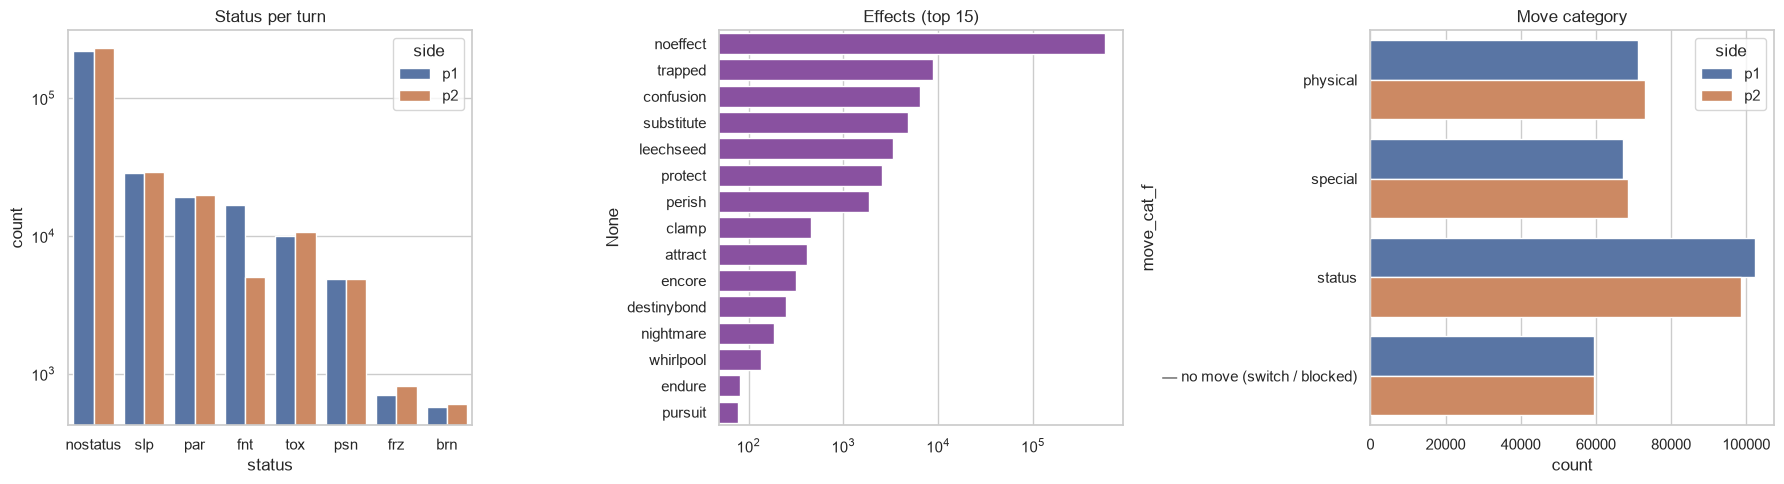

In [15]:
# Counts are aggregated first and then plotted (countplot on 600k rows is slow)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
st_counts = tl.groupby(["status", "side"]).size().reset_index(name="count")
sns.barplot(data=st_counts, x="status", y="count", hue="side", ax=axes[0], order=tl["status"].value_counts().index)
axes[0].set_title("Status per turn"); axes[0].set_yscale("log")
eff = Counter(e for es in tl["effects"] for e in es)
eff = pd.Series(eff).sort_values(ascending=False).head(15)
sns.barplot(x=eff.values, y=eff.index, ax=axes[1], color="#8e44ad"); axes[1].set_title("Effects (top 15)"); axes[1].set_xscale("log")
tl["move_cat_f"] = tl["move_cat"].fillna("— no move (switch / blocked)")
cat_counts = tl.groupby(["move_cat_f", "side"]).size().reset_index(name="count")
sns.barplot(data=cat_counts, y="move_cat_f", x="count", hue="side", ax=axes[2]); axes[2].set_title("Move category")
plt.tight_layout(); plt.show()

### 5.2 Null move: switch, KO or "can't move"?

`move_details = null` mixes different cases. We try to tell them apart by comparing the active Pokémon
at turn *t* with the one at turn *t-1*.

In [16]:
tl = tl.sort_values(["battle_id", "side", "turn"]).reset_index(drop=True)
g = tl.groupby(["battle_id", "side"])
tl["prev_name"] = g["name"].shift()
tl["prev_status"] = g["status"].shift()
tl["switched"] = tl["prev_name"].notna() & (tl["name"] != tl["prev_name"])

# Vectorised labelling: rules are applied from lowest to highest priority,
# so later assignments win (move > switch after KO > voluntary switch > blocked > other).
# Note: missing moves are NaN in the DataFrame, hence .notna() and not `is not None`.
action = pd.Series("other", index=tl.index, dtype=object)
blocked = tl["status"].isin(["slp", "frz", "par"])
action[blocked] = "blocked (" + tl.loc[blocked, "status"] + ")"
action[tl["switched"]] = "voluntary switch"
action[tl["switched"] & (tl["prev_status"] == "fnt")] = "switch after KO"
action[tl["move"].notna()] = "move"
tl["action"] = action
display(pd.crosstab(tl["action"], tl["side"], normalize="columns").round(4))

side,p1,p2
action,,
blocked (frz),0.0004,0.0006
blocked (par),0.0028,0.0028
blocked (slp),0.0063,0.0063
move,0.8021,0.8013
other,0.0126,0.0140
switch after KO,0.0274,0.0073
voluntary switch,0.1484,0.1677


### 5.3 HP difference over the turns, by outcome

For each side we track the **total remaining HP** turn by turn (6 = all Pokémon at full HP; P2's unseen
Pokémon are assumed at full HP) and plot the P1 - P2 difference, separately for wins and losses.

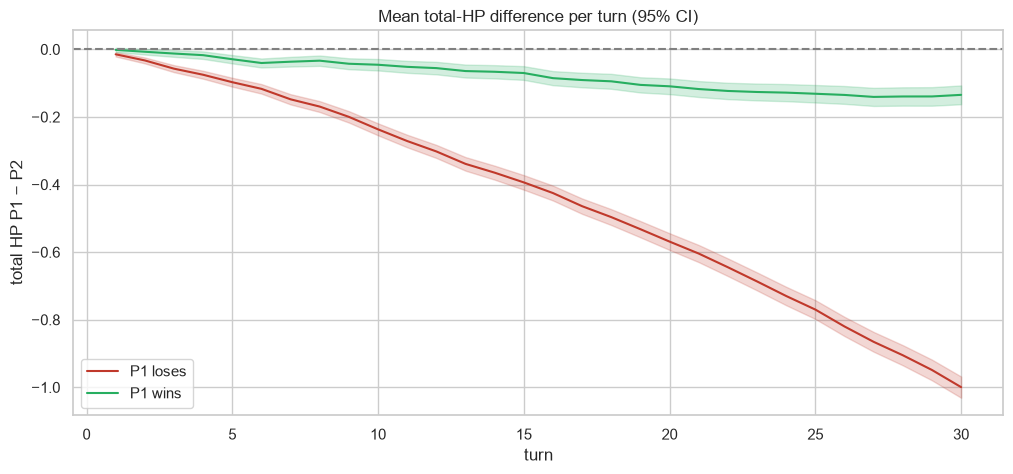

In [17]:
# Every time a Pokémon is observed, the side's total HP changes by (current HP - last known HP of that Pokémon)
tl["hp_delta"] = tl["hp_pct"] - tl.groupby(["battle_id", "side", "name"])["hp_pct"].shift().fillna(1.0)
tl["hp_total"] = 6 + tl.groupby(["battle_id", "side"])["hp_delta"].cumsum()

hp_turn = tl.pivot_table(index=["battle_id", "turn"], columns="side", values="hp_total")
hp_turn["hp_diff"] = hp_turn["p1"] - hp_turn["p2"]
hp_turn = hp_turn.join(pd.Series({x["battle_id"]: x["player_won"] for x in train}, name="player_won"), on="battle_id")
curve = hp_turn.groupby(["turn", "player_won"])["hp_diff"].agg(["mean", "sem"]).reset_index()

plt.figure(figsize=(12, 5))
for won, color, label in [(0, "#c0392b", "P1 loses"), (1, "#27ae60", "P1 wins")]:
    c = curve[curve["player_won"] == won]
    plt.plot(c["turn"], c["mean"], color=color, label=label)
    plt.fill_between(c["turn"], c["mean"] - 1.96 * c["sem"], c["mean"] + 1.96 * c["sem"], color=color, alpha=0.2)
plt.axhline(0, ls="--", c="grey"); plt.xlabel("turn"); plt.ylabel("total HP P1 − P2")
plt.title("Mean total-HP difference per turn (95% CI)"); plt.legend(); plt.show()

### 5.4 State "at turn 30": KOs, revealed Pokémon, remaining HP

For each battle we reconstruct, per side, the **last known HP of every Pokémon seen** and how many are KO.
For P2 the Pokémon not yet revealed (6 - seen) are unknown: this is important information.

In [18]:
# Last observed row of each Pokémon (drop_duplicates is much faster than groupby + "last")
last = (tl.sort_values("turn", kind="stable")
          .drop_duplicates(["battle_id", "side", "name"], keep="last")
          [["battle_id", "side", "name", "hp_pct", "status"]]
          .rename(columns={"hp_pct": "last_hp", "status": "last_status"}))
last["fainted"] = last["last_status"] == "fnt"
last["is_statused"] = ~last["last_status"].isin(["nostatus", "fnt"])
summ = last.groupby(["battle_id", "side"]).agg(
    seen=("name", "size"), ko=("fainted", "sum"), hp_seen=("last_hp", "sum"),
    statused=("is_statused", "sum")).unstack("side")
summ.columns = [f"{side}_{c}" for c, side in summ.columns]
# Unseen Pokémon are assumed at full HP
summ["p1_hp_total"] = summ["p1_hp_seen"] + (6 - summ["p1_seen"])
summ["p2_hp_total"] = summ["p2_hp_seen"] + (6 - summ["p2_seen"])
summ["diff_ko"] = summ["p1_ko"] - summ["p2_ko"]
summ["diff_hp_total"] = summ["p1_hp_total"] - summ["p2_hp_total"]
summ["diff_statused"] = summ["p1_statused"] - summ["p2_statused"]
summ = summ.join(pd.Series({x["battle_id"]: x["player_won"] for x in train}, name="player_won"))
summ.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
p1_seen,10000.0,5.41,0.77,1.00,5.00,6.00,6.00,6.0
p2_seen,10000.0,5.39,0.79,1.00,5.00,6.00,6.00,6.0
p1_ko,10000.0,1.69,1.43,0.00,1.00,1.00,3.00,6.0
p2_ko,10000.0,0.50,0.77,0.00,0.00,0.00,1.00,5.0
p1_hp_seen,10000.0,2.84,1.25,0.00,1.94,2.85,3.75,6.0
p2_hp_seen,10000.0,3.39,1.06,0.17,2.66,3.41,4.14,6.0
p1_statused,10000.0,1.04,0.91,0.00,0.00,1.00,2.00,5.0
p2_statused,10000.0,1.35,1.00,0.00,1.00,1.00,2.00,6.0
p1_hp_total,10000.0,3.43,1.33,0.00,2.52,3.53,4.45,6.0
p2_hp_total,10000.0,4.00,1.05,0.34,3.29,4.08,4.79,6.0


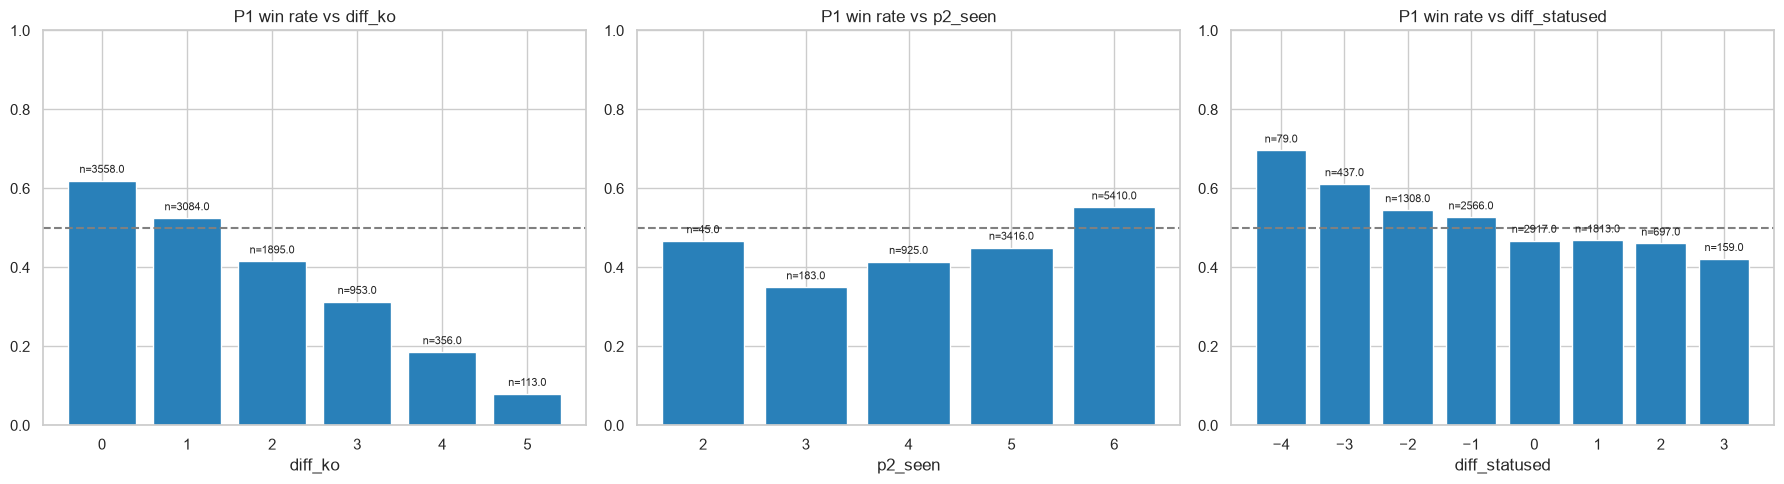

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["diff_ko", "p2_seen", "diff_statused"]):
    t = summ.groupby(col)["player_won"].agg(["mean", "size"])
    t = t[t["size"] >= 30]
    ax.bar(t.index, t["mean"], color="#2980b9"); ax.axhline(0.5, ls="--", c="grey")
    ax.set_title(f"P1 win rate vs {col}"); ax.set_xlabel(col); ax.set_ylim(0, 1)
    for i, (m, n) in t.iterrows():
        ax.text(i, m + 0.02, f"n={n}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

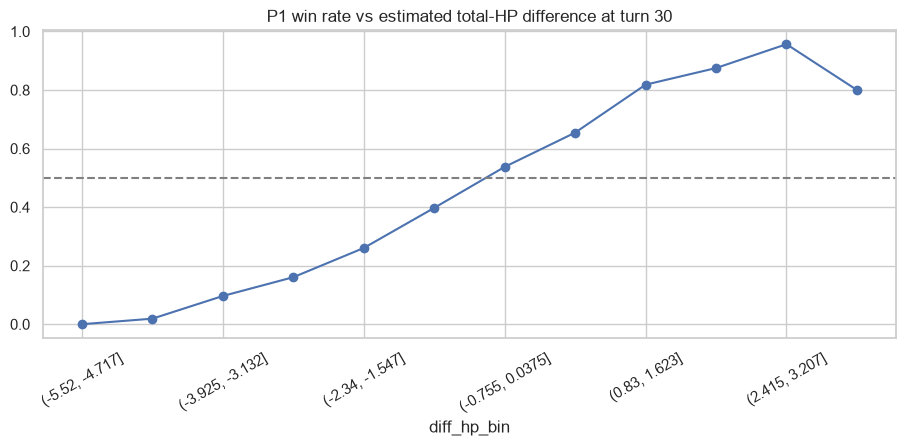

,mean,size
diff_hp_bin,,
"(-5.52, -4.717]",0.000000,16
"(-4.717, -3.925]",0.018868,53
"(-3.925, -3.132]",0.096386,166
"(-3.132, -2.34]",0.160521,461
"(-2.34, -1.547]",0.260298,1141
"(-1.547, -0.755]",0.397311,2157
"(-0.755, 0.0375]",0.537369,2957
"(0.0375, 0.83]",0.654380,2089
"(0.83, 1.623]",0.818182,748


In [20]:
summ["diff_hp_bin"] = pd.cut(summ["diff_hp_total"], bins=12)
t = summ.groupby("diff_hp_bin", observed=True)["player_won"].agg(["mean", "size"])
ax = t["mean"].plot(marker="o", figsize=(11, 4)); ax.axhline(0.5, ls="--", c="grey")
ax.set_title("P1 win rate vs estimated total-HP difference at turn 30"); plt.xticks(rotation=30); plt.show()
t

### 5.5 Boosts and setup moves

In [21]:
boost_cols = [c for c in tl.columns if c.startswith("boost_")]
# Max positive boost reached for each stat, summed over stats (vectorised groupby, no apply)
bt = (tl[boost_cols].clip(lower=0)
        .groupby([tl["battle_id"], tl["side"]]).max()
        .sum(axis=1).unstack("side"))
bt.columns = ["p1_max_boost", "p2_max_boost"]
bt["diff_boost"] = bt["p1_max_boost"] - bt["p2_max_boost"]
bt = bt.join(summ["player_won"])
t = bt.groupby(bt["diff_boost"].clip(-4, 4))["player_won"].agg(["mean", "size"])
display(t)

,mean,size
diff_boost,,
-4,0.498430,1274
-3,0.547945,219
-2,0.544256,1593
-1,0.528302,318
0,0.500000,3162
1,0.467290,321
2,0.470956,1601
3,0.467532,231
4,0.481655,1281


### 5.6 Data limitation: KO records are asymmetric between P1 and P2

In section 5.4 P1 has on average many more KOs than P2 (1.69 vs 0.50 per battle), even though the target is
perfectly balanced. If KOs were recorded in the same way for both players, P2 should lose about as many
Pokémon as P1 does. Here we quantify the asymmetry:
- rows where the active Pokémon is fainted (`fnt`), per side;
- mean KOs per battle, split by outcome (even in battles **won by P1**);
- switch-outs with HP ≤ 10% that are *not* followed by a `fnt` record (a Pokémon possibly KO'd but not marked);
- how each side's KO count correlates with the target.

,p1,p2
fnt rows (total),16882.000,5040.000
mean KO / battle (P1 loses),1.980,0.487
mean KO / battle (P1 wins),1.397,0.521
low-HP exits not marked fnt,508.000,1364.000
"corr(KO count, player_won)",-0.204,0.022


diff_ko range: -1 to 6
mean diff_hp_total at turn 30 when P1 wins: -0.135


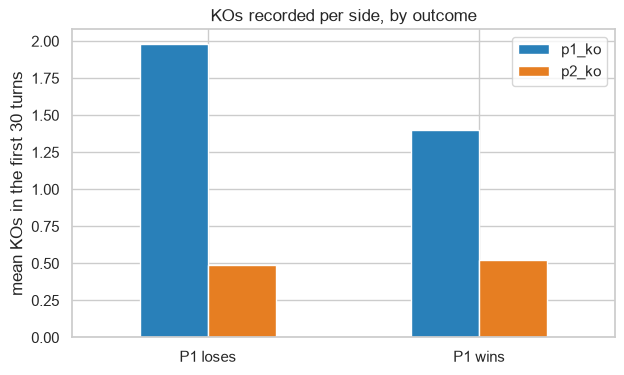

In [22]:
# Fainted rows per side, split by outcome
fnt_rows = tl[tl["status"] == "fnt"].groupby(["player_won", "side"]).size().unstack("side")

# Low-HP exits: the Pokémon leaves the field with <= 10% HP without ever being marked as fainted
prev_hp = tl.groupby(["battle_id", "side"])["hp_pct"].shift()
low_exit = tl["switched"] & (prev_hp <= 0.1) & (tl["prev_status"] != "fnt")

ko_report = pd.DataFrame({
    "fnt rows (total)": tl[tl["status"] == "fnt"]["side"].value_counts(),
    "mean KO / battle (P1 loses)": summ.loc[summ["player_won"] == 0, ["p1_ko", "p2_ko"]].mean().set_axis(["p1", "p2"]),
    "mean KO / battle (P1 wins)": summ.loc[summ["player_won"] == 1, ["p1_ko", "p2_ko"]].mean().set_axis(["p1", "p2"]),
    "low-HP exits not marked fnt": tl.loc[low_exit, "side"].value_counts(),
    "corr(KO count, player_won)": summ[["p1_ko", "p2_ko"]].corrwith(summ["player_won"]).set_axis(["p1", "p2"]),
}).T.round(3)
display(ko_report)
print("diff_ko range:", summ["diff_ko"].min(), "to", summ["diff_ko"].max())
print("mean diff_hp_total at turn 30 when P1 wins:", summ.loc[summ["player_won"] == 1, "diff_hp_total"].mean().round(3))

mean_ko = summ.groupby("player_won")[["p1_ko", "p2_ko"]].mean()
mean_ko.index = ["P1 loses", "P1 wins"]
ax = mean_ko.plot.bar(rot=0, color=["#2980b9", "#e67e22"], figsize=(7, 4))
ax.set_ylabel("mean KOs in the first 30 turns"); ax.set_title("KOs recorded per side, by outcome")
plt.show()

#### Estimating "hidden" KOs: Pokémon that left the field and never came back

A Pokémon whose last appearance is **before turn 30** and that is never marked `fnt` either was switched out
and simply not used again, or was KO'd without a `fnt` record. We count these "vanished" Pokémon per side,
split by their HP at the last appearance, and check how much of the KO gap they close.

,vanished P1 / battle,vanished P2 / battle,KO gap (P1 - P2) recorded,KO gap (P1 - P2) with vanished,"corr(P1 est, won)","corr(P2 est, won)"
last HP <=,,,,,,
0.10,0.024,0.125,1.184,1.084,-0.204,0.046
0.25,0.157,0.512,1.184,0.829,-0.209,0.096
0.50,0.512,1.203,1.184,0.493,-0.214,0.132
1.00,2.810,3.920,1.184,0.074,-0.118,0.118


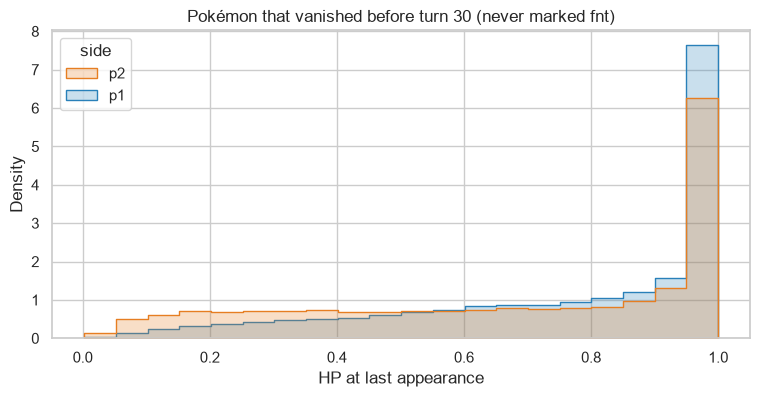

In [23]:
# Last appearance of every Pokémon seen (turn included)
last_seen = (tl.sort_values("turn", kind="stable")
               .drop_duplicates(["battle_id", "side", "name"], keep="last")
               [["battle_id", "side", "name", "turn", "hp_pct", "status"]])
vanished = last_seen[(last_seen["turn"] < 30) & (last_seen["status"] != "fnt")]

rows = []
for thr in [0.1, 0.25, 0.5, 1.0]:
    cnt = (vanished[vanished["hp_pct"] <= thr].groupby(["battle_id", "side"]).size()
             .unstack("side").reindex(summ.index).fillna(0))
    est = summ[["p1_ko", "p2_ko"]].values + cnt[["p1", "p2"]].values
    est = pd.DataFrame(est, index=summ.index, columns=["p1", "p2"])
    rows.append({
        "last HP <=": thr,
        "vanished P1 / battle": cnt["p1"].mean(), "vanished P2 / battle": cnt["p2"].mean(),
        "KO gap (P1 - P2) recorded": (summ["p1_ko"] - summ["p2_ko"]).mean(),
        "KO gap (P1 - P2) with vanished": (est["p1"] - est["p2"]).mean(),
        "corr(P1 est, won)": est["p1"].corr(summ["player_won"]),
        "corr(P2 est, won)": est["p2"].corr(summ["player_won"]),
    })
display(pd.DataFrame(rows).set_index("last HP <=").round(3))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=vanished, x="hp_pct", hue="side", bins=20, stat="density", common_norm=False,
             element="step", ax=ax, palette={"p1": "#2980b9", "p2": "#e67e22"})
ax.set_xlabel("HP at last appearance"); ax.set_title("Pokémon that vanished before turn 30 (never marked fnt)")
plt.show()

**Takeaway.**
- The asymmetry is real and identical in train and test (≈1.69 vs ≈0.51 recorded KOs per battle), so a model
  trained on these features still transfers to the test set: it learns P(win | *recorded* KOs).
- Low-HP exits (≤ 10%) explain only a small part of the gap (≈0.13 per battle for P2 vs a gap of ≈1.18).
- P2 Pokémon vanish with low or medium HP much more often than P1's (last HP ≤ 0.5: 1.20 vs 0.51 per battle),
  while P1's vanished Pokémon are mostly healthy switch-outs. Counting P2 Pokémon that vanished with HP ≤ 0.5 as
  KOs shrinks the gap from 1.18 to 0.49 and raises the correlation of P2's KO estimate with the target from
  0.02 to 0.13. Part of P2's KOs are therefore probably not recorded, but a gap of ≈0.5 remains:
  **the cause of the asymmetry is not established.**

Consequences:
- `diff_*` features (P1 - P2) are **not symmetric**: keep the P1 and P2 values as separate features too.
- Model interpretation: "P2 KOs do not matter" is a property of the recorded data, not of the game.
- Add the "vanished" counts as P2 KO proxies; the HP threshold (0.25 / 0.5) is to be chosen in CV, not here.
- **In the report, the P1 - P2 difference must be cited as a data limitation.**

## 6. Correlations between quick features

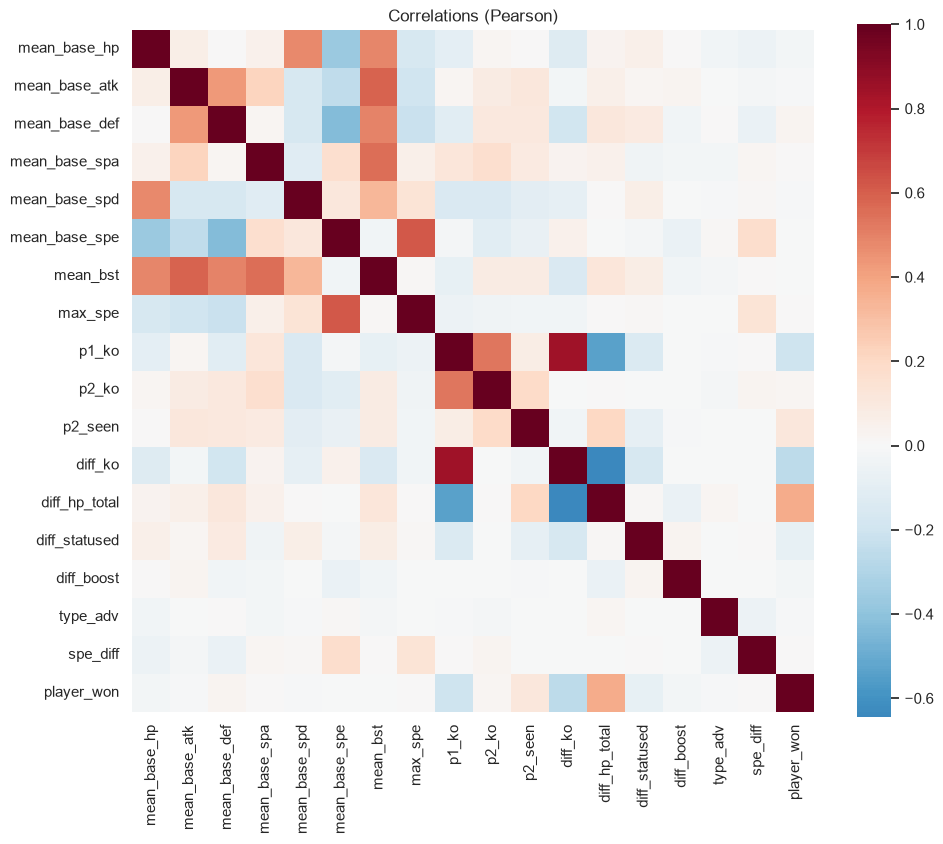

diff_hp_total    0.374
diff_ko         -0.256
p1_ko           -0.204
p2_seen          0.109
diff_statused   -0.084
mean_base_def    0.029
diff_boost      -0.025
mean_base_hp    -0.024
p2_ko            0.022
mean_base_spd   -0.014
type_adv        -0.011
mean_base_atk   -0.009
max_spe          0.006
spe_diff         0.006
mean_base_spa    0.006
mean_base_spe    0.003
mean_bst         0.000
Name: player_won, dtype: float64

In [24]:
quick = team.drop(columns="player_won").join(
    summ[["p1_ko", "p2_ko", "p2_seen", "diff_ko", "diff_hp_total", "diff_statused"]]).join(
    bt[["diff_boost"]]).join(lead.set_index(pd.Index([x["battle_id"] for x in train]))[["type_adv", "spe_diff"]]).join(summ["player_won"])
corr = quick.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True)
plt.title("Correlations (Pearson)"); plt.show()
corr["player_won"].drop("player_won").sort_values(key=abs, ascending=False).round(3)

## 7. Train vs test sanity check (descriptive only)

We check that test is "similar" to train and how many test species never appear in train
(this helps decide how to handle unknown categories, **not** to choose features).

In [25]:
def species_set(data):
    s = set()
    for x in data:
        s |= {p["name"] for p in x["p1_team_details"]}
        s.add(x["p2_lead_details"]["name"])
        for t in x["battle_timeline"]:
            s.add(t["p1_pokemon_state"]["name"]); s.add(t["p2_pokemon_state"]["name"])
    return s

sp_tr, sp_te = species_set(train), species_set(test)
print(f"train species: {len(sp_tr)} | test: {len(sp_te)} | test only: {sorted(sp_te - sp_tr)}")

train species: 247 | test: 242 | test only: ['alakazammega', 'celebi', 'charizardmegay', 'kakuna', 'weedle']


## 8. Conclusions and guidance for feature engineering

**Data quality**
- 10,000 train / 5,000 test battles, unique ids, always 6 P1 Pokémon and 30 turns, no missing items.
- 360 (train) / 204 (test) P1 Pokémon are below level 100: their effect on the outcome is still to be measured.
- 5 species appear only in test (`alakazammega`, `charizardmegay`, `celebi`, `kakuna`, `weedle`; Mega forms do
  not exist in Gen 2) → feature code needs a fallback for unknown species.

**Target**
- Perfectly balanced (50/50) → accuracy is a sensible metric, majority baseline = 50%.

**Static information (P1 team, P2 lead) carries almost no signal on its own**
- Mean team stats: |Pearson r| ≤ 0.03 with the target.
- Species win rates lie between ~0.47 and 0.57 (best: Misdreavus 0.566 ± 0.035); items: Leftovers dominates,
  the others have very wide confidence intervals.
- Lead matchup: type advantage shows no monotonic trend (r = -0.011); speed advantage moves the win rate by
  ~1.6 points only.
- → static features are useful mainly in interaction with the battle state; species target encoding, if used,
  must be fitted **inside the CV folds**.

**The timeline is where the signal is**
- `diff_hp_total` (estimated total remaining HP, P1 - P2) is the strongest feature (r = 0.374): win rate goes
  from ~2% at -4 to ~54% around 0 and 82-96% at +1/+3.
- The HP-difference curves of wins and losses diverge already in the first 5-10 turns and keep growing →
  add **trend features** (slope over the last 5/10 turns), not only the state at turn 30.
- P1 KOs (r = -0.20): win rate drops from 62% (0 extra KOs) to 8% (5 extra KOs).
- Revealed P2 Pokémon (r = 0.11): P1 wins 55% when all 6 are seen, 35-41% when only 3-4 are seen.
- Status: more statused P1 Pokémon is a small disadvantage (r = -0.08).
- Boosts: weak and counter-intuitive (more P1 boosts → slightly lower win rate); ±2/±4 peaks are probably Curse
  (+atk +def -spe) → split boosts by stat.
- Null moves: ~80% real moves, 15-17% voluntary switches, ~1% blocked (sleep/paralysis/freeze), ~1.3% "other"
  still to explain (recharge? flinch?).

**Data limitation: asymmetric KO records (section 5.6)**
- Fainted rows: 16,882 for P1 vs 5,040 for P2; even in battles won by P1, P1 has ~1.40 KOs vs ~0.52 for P2.
- `diff_ko` never goes below -1, P2's KO count is almost uncorrelated with the target (r = 0.02), and the HP
  difference stays negative even in P1 wins (-0.135 at turn 30).
- The asymmetry is the same in train and test, so it does not hurt predictions; it hurts interpretation and
  linear `diff_*` features, which force equal and opposite weights on P1 and P2.
- Low-HP exits (≤ 10%) explain little (≈0.13 per battle). Counting P2 Pokémon that vanished with HP ≤ 0.5 as
  KOs shrinks the gap from 1.18 to 0.49 and raises P2's KO correlation from 0.02 to 0.13: part of P2's KOs
  are probably unrecorded, but **the cause of the asymmetry is not established**.
- → keep P1 and P2 features separate, add "vanished" counts as P2 KO proxies (threshold chosen in CV).
- **In the report, the P1 - P2 difference must be cited as a data limitation.**

**Next steps for feature engineering**
1. Battle state at turn 30 per side: KOs, "vanished" Pokémon (P2 KO proxy), estimated total HP, revealed Pokémon, active status.
2. Trends over the last 5/10 turns (HP difference, KOs).
3. Action counts: voluntary switches, switches after KO, blocked turns.
4. Sleep / Toxic counters, boosts per stat, relevant effects (substitute, leech seed, perish, trapped).
5. Matchup of the active Pokémon at turn 30 (type, speed) and P1 team coverage against the P2 Pokémon seen.
6. Damage estimated with the Gen 2 formula; species target encoding inside the folds.